In [1]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
def plot_learning_curve(history):
    # Graficar precisión
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()


In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)

1 Physical GPUs, 1 Logical GPUs


In [4]:
(X_train, y_train), (X_test_full, y_test_full) = tf.keras.datasets.mnist.load_data()

In [5]:
X_test, X_val, y_test, y_val= train_test_split(
    X_test_full, y_test_full, test_size=0.50, random_state=42
)

In [6]:
X_train.shape, X_test.shape, X_val.shape

((60000, 28, 28), (5000, 28, 28), (5000, 28, 28))

In [7]:
for row in X_train[0]:
  print(" ".join(f"{val:3}" for val in row))

  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127   0   0   0   0
  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64   0   0   0   0
  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0   0   0   0   0
  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   0   0   0   0   0   0   0 

In [8]:
X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

In [9]:
X_train[0].shape

(28, 28)

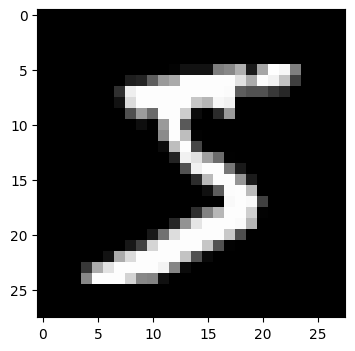

In [10]:
plt.figure(figsize=(4,4))
plt.imshow(X_train[0], cmap="gray", vmin = 0, vmax=1.0)
plt.show()

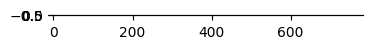

In [11]:
plt.figure(figsize=(4,4))
plt.imshow(X_train[0].ravel().reshape(1, 784),  cmap="gray", vmin = 0, vmax=1.0)
plt.show()

In [12]:
(X_train.shape[1],)

(28,)

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = model.fit(
    X_train,
    y_train,
    epochs = 20,
    batch_size = 32,
    validation_data = (X_val, y_val)
)

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9294 - loss: 0.2400 - val_accuracy: 0.9604 - val_loss: 0.1291
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9685 - loss: 0.1022 - val_accuracy: 0.9698 - val_loss: 0.0981
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9780 - loss: 0.0711 - val_accuracy: 0.9718 - val_loss: 0.0841
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9820 - loss: 0.0545 - val_accuracy: 0.9744 - val_loss: 0.0811
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9862 - loss: 0.0416 - val_accuracy: 0.9752 - val_loss: 0.0905
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9887 - loss: 0.0348 - val_accuracy: 0.9730 - val_loss: 0.1036
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9903 - loss: 0.0295 - val_accuracy: 0.9730 - val_loss: 0.0904
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9918 - loss: 0.0248 -

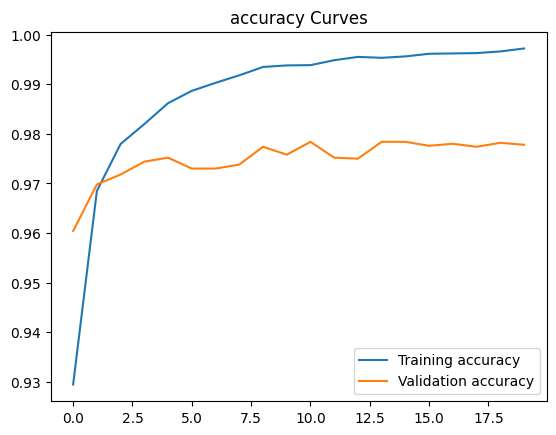

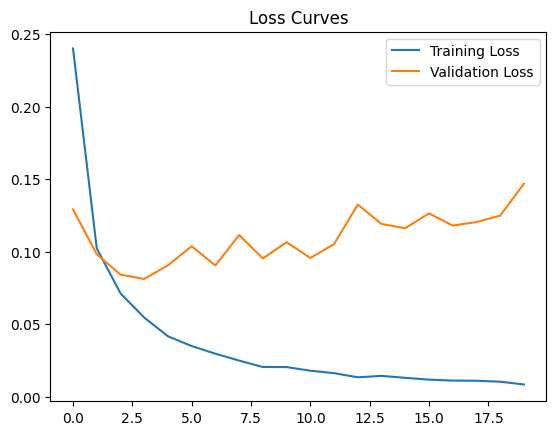

In [16]:
plot_learning_curve(history)

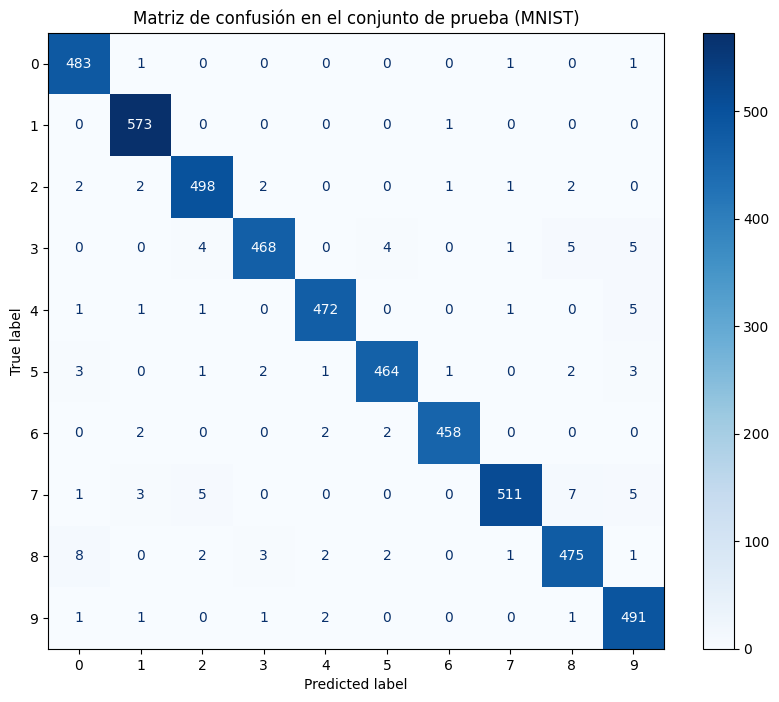

In [17]:

# Obtener las probabilidades predichas para el conjunto de prueba
probabilidades = model.predict(X_test, verbose=0)

# Para multiclase, tomamos el índice con la probabilidad más alta
y_pred = np.argmax(probabilidades, axis=1)

# Graficar la matriz de confusión
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[str(i) for i in range(10)],
    cmap="Blues",
    ax=ax,
)
plt.title("Matriz de confusión en el conjunto de prueba (MNIST)")
plt.grid(False)
plt.show()

# Modelo 2

In [18]:
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model2.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [19]:
model2.fit(
    X_train,
    y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (X_val, y_val)
)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7480 - loss: 0.7938 - val_accuracy: 0.8844 - val_loss: 0.5115
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9006 - loss: 0.4373 - val_accuracy: 0.9178 - val_loss: 0.3677
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9277 - loss: 0.3167 - val_accuracy: 0.9318 - val_loss: 0.2980
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9411 - loss: 0.2493 - val_accuracy: 0.9382 - val_loss: 0.2727
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9504 - loss: 0.2082 - val_accuracy: 0.9422 - val_loss: 0.2643
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9561 - loss: 0.1755 - val_accuracy: 0.9368 - val_loss: 0.2687
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9619 - loss: 0.1512 - val_accuracy: 0.9386 - val_loss: 0.2564
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9667 - loss: 0.1302 - 

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


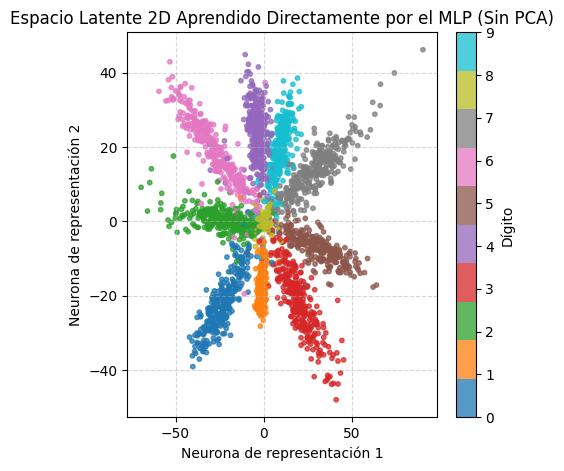

In [22]:
extractor = tf.keras.Model(
    inputs = model2.inputs,
    outputs = model2.get_layer("rep_2d").output
)

n = 3000
x_visual = X_val[:n]
y_visual = y_val[:n]

puntos2d = extractor.predict(x_visual)

plt.figure(figsize=(5,5))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=10,
    alpha=0.75,
)
plt.title("Espacio Latente 2D Aprendido Directamente por el MLP (Sin PCA)")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
plt.colorbar(scatter_plot, ticks=range(10), label="Dígito")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()